# Lip Reading (Viseme–Phoneme Adaptive Model) — Colab Orchestrator

This notebook **only orchestrates** the pipeline that lives in the repository. It never edits or patches
repository files: every step calls the repo's own command-line tools with flags.

| Step | Repo tool |
|---|---|
| Mouth-crop preprocessing | `scripts/preprocess.py` |
| Training (+ validation every epoch, + test on the best checkpoint) | `main.py train` |
| Stand-alone evaluation | `main.py evaluate` |
| Per-utterance demo | `main.py inference` |

**How to use:** set the values in **1. Settings**, then *Runtime → Run all*. Each cell skips work that is
already done, so re-running after a disconnect resumes where it stopped.

**Where things are stored**

```
MyDrive/
├── Training_Artifacts/                          # existing raw GRID archives (read only)
└── Lipreading_advanced_preprocessing/           # everything this notebook produces
    ├── preprocessed/<PREPROCESS_TAG>/           #   sN_preprocessed.tar.gz  (.npy crops + .meta.npz)
    ├── alignments/                              #   sN_alignments.tar.gz    (for copying to a local machine)
    └── runs/<RUN_NAME>/                         #   checkpoints, metrics CSV, test results, plots, logs
```

Working copies live on the Colab VM's local disk (`/content/data`), which is much faster than reading thousands
of small files from Drive. Drive is used only for inputs and for everything that must survive the session.

## 1. Settings
The only cell you normally edit. Speakers are space-separated (`s1 s2 s3`).

- **Preprocessing:** `PREPROCESS_SPEAKERS` are cropped from the raw videos and archived to Drive. Speakers
  whose archive already exists on Drive are skipped. Crop settings define `PREPROCESS_TAG`, so changing them
  writes to a new folder instead of mixing crop styles.
- **Training:** set `RUN_TRAINING = True` to train/evaluate. The train/val/test speakers must already be
  preprocessed (in this or an earlier session). The default split is the unseen-speaker protocol used by
  LipNet: validate on s20 and s22, test on s1 and s2, train on the other 29 speakers.
- **Model:** `MODEL_TYPE` (full / baseline / visual_only), `SEQ_MODEL` (temporal encoder), `VISUAL_POOL`
  and `GATE` (fusion gate; `intrinsic-extrinsic` is the proposed one, the others are baselines). Train one
  `RUN_NAME` per configuration to compare them.
- **Runs:** each `RUN_NAME` gets its own folder on Drive. Re-running with the same name and `RESUME = True`
  continues from that run's `last_model.pth`.
- **Ablation:** set `TRAINING_MODE = "ablation"` to train and evaluate several configurations one after
  another with identical data and settings (`scripts/run_ablation.py`), each in
  `runs/<ABLATION_NAME>/<configuration>/`, followed by a comparison table (`scripts/compare_runs.py`).
  `ABLATION_PRESET`: `seq` (hybrid vs bilstm vs transformer vs conformer), `gate` (the proposed gate vs the
  four baseline gates, plus the baseline and visual_only model types), `pool` (avg vs flatten), or `custom`
  (list `model_type/seq_model/visual_pool/gate` entries in `ABLATION_CONFIGS`). `ABLATION_TRAIN_SPEAKERS`
  (if not empty) and `ABLATION_EPOCHS` make a cheaper reduced ablation; validation/test speakers stay the same.
  Re-running continues: finished configurations are skipped, an interrupted one resumes.

In [1]:
# ---- Code ----
REPO_URL = "https://github.com/Rathi4research/Lipreading_Viseme_New.git"  #@param {type:"string"}
BRANCH = "training-v2"  #@param {type:"string"}

# ---- Google Drive ----
RAW_DATA_DIR = "/content/drive/MyDrive/Training_Artifacts"  #@param {type:"string"}
OUTPUT_DIR = "/content/drive/MyDrive/Lipreading_advanced_preprocessing"  #@param {type:"string"}

# ---- Preprocessing ----
GRID_ALL = " ".join(f"s{i}" for i in range(1, 35) if i != 21)   # s21 was never released
RUN_PREPROCESSING = False  #@param {type:"boolean"}
PREPROCESS_SPEAKERS = GRID_ALL  #@param {type:"raw"}
CROP_MODE = "aligned"  #@param ["aligned", "square", "tight"]
CROP_SCALE = 1.4  #@param {type:"number"}
STORED_SIZE = 96  #@param {type:"integer"}

# ---- Training / evaluation ----
RUN_TRAINING = True  #@param {type:"boolean"}
TRAINING_MODE = "ablation"  #@param ["single", "ablation"]
RUN_NAME = "v2-full-hybrid-ie"  #@param {type:"string"}
RESUME = True  #@param {type:"boolean"}
VAL_SPEAKERS = "s20 s22"  #@param {type:"string"}
TEST_SPEAKERS = "s1 s2"  #@param {type:"string"}
TRAIN_SPEAKERS = " ".join(s for s in GRID_ALL.split() if s not in (VAL_SPEAKERS + " " + TEST_SPEAKERS).split())  #@param {type:"raw"}
MODEL_TYPE = "full"  #@param ["full", "baseline", "visual_only"]
SEQ_MODEL = "hybrid"  #@param ["hybrid", "bilstm", "transformer", "conformer"]
VISUAL_POOL = "avg"  #@param ["avg", "flatten"]
GATE = "intrinsic-extrinsic"  #@param ["intrinsic-extrinsic", "ambiguity", "entropy", "learned", "hard"]
NUM_EPOCHS = 30  #@param {type:"integer"}
BATCH_SIZE = 16  #@param {type:"integer"}
LEARNING_RATE = 3e-4  #@param {type:"number"}
AUGMENT = True  #@param {type:"boolean"}
AMP = True  #@param {type:"boolean"}
SEED = 42  #@param {type:"integer"}
NUM_WORKERS = 2  #@param {type:"integer"}
MIN_DETECTED_RATIO = 0.5  #@param {type:"number"}
CORRUPT_RATIO = 0.3  #@param {type:"number"}
DEMO_SAMPLES = 3  #@param {type:"integer"}

# ---- Ablation (TRAINING_MODE = "ablation") ----
ABLATION_NAME = "ablation-seq"  #@param {type:"string"}
ABLATION_PRESET = "seq"  #@param ["seq", "gate", "pool", "custom"]
ABLATION_CONFIGS = "full/hybrid/avg/intrinsic-extrinsic full/bilstm/avg/intrinsic-extrinsic"  #@param {type:"string"}
ABLATION_TRAIN_SPEAKERS = "s3 s4 s5 s6 s7 s8 s9 s10"  #@param {type:"string"}
ABLATION_EPOCHS = 15  #@param {type:"integer"}

# ---- Derived paths (no need to edit) ----
PREPROCESS_TAG = f"{CROP_MODE}_scale{CROP_SCALE}_{STORED_SIZE}px"
REPO_DIR = "/content/Lipreading_Viseme_New"
LOCAL_DATA = "/content/data"                       # fast local working copy
VIDEO_DIR = f"{LOCAL_DATA}/videos"
ALIGN_DIR = f"{LOCAL_DATA}/alignments"
NPY_DIR = f"{LOCAL_DATA}/preprocessed_lips"
DRIVE_PREPROCESSED = f"{OUTPUT_DIR}/preprocessed/{PREPROCESS_TAG}"
DRIVE_ALIGNMENTS = f"{OUTPUT_DIR}/alignments"
SINGLE_RUN = RUN_TRAINING and TRAINING_MODE == "single"
ABLATION_RUN = RUN_TRAINING and TRAINING_MODE == "ablation"
if ABLATION_RUN and ABLATION_TRAIN_SPEAKERS.strip():
    TRAIN_SPEAKERS = ABLATION_TRAIN_SPEAKERS
if ABLATION_RUN:
    NUM_EPOCHS = ABLATION_EPOCHS
RUN_DIR = f"{OUTPUT_DIR}/runs/{ABLATION_NAME if ABLATION_RUN else RUN_NAME}"
LANDMARK_FILE = f"{REPO_DIR}/shape_predictor_68_face_landmarks.dat"

split = lambda s: s.split()
PREP_SPK, TRAIN_SPK, VAL_SPK, TEST_SPK = map(split, (PREPROCESS_SPEAKERS, TRAIN_SPEAKERS, VAL_SPEAKERS, TEST_SPEAKERS))
MODEL_SPK = sorted(set(TRAIN_SPK + VAL_SPK + TEST_SPK), key=lambda s: int(s[1:])) if RUN_TRAINING else []
print("Preprocessing tag :", PREPROCESS_TAG)
print("Preprocess        :", PREP_SPK if RUN_PREPROCESSING else "skipped")
print("Train/val/test    :", (TRAIN_SPK, VAL_SPK, TEST_SPK) if RUN_TRAINING else "skipped")
print("Training mode     :", TRAINING_MODE if RUN_TRAINING else "off",
      f"(preset {ABLATION_PRESET}, {NUM_EPOCHS} epochs)" if ABLATION_RUN else "")
print("Run folder        :", RUN_DIR)

Preprocessing tag : aligned_scale1.4_96px
Preprocess        : skipped
Train/val/test    : (['s3', 's4', 's5', 's6', 's7', 's8', 's9', 's10'], ['s20', 's22'], ['s1', 's2'])
Training mode     : ablation (preset seq, 15 epochs)
Run folder        : /content/drive/MyDrive/Lipreading_advanced_preprocessing/runs/ablation-seq


## 2. Check the GPU
Training needs a CUDA GPU (*Runtime → Change runtime type → T4 GPU* or better). Preprocessing only uses the
CPU, so this is just a warning when training is off.

In [2]:
import torch, os
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0), f"| {torch.cuda.get_device_properties(0).total_memory / 1e9:.0f} GB")
elif RUN_TRAINING:
    raise RuntimeError("No GPU. Runtime -> Change runtime type -> select a GPU, then Run all again.")
else:
    print("No GPU attached (fine for preprocessing only).")
print("CPU cores:", os.cpu_count())

GPU: NVIDIA L4 | 24 GB
CPU cores: 12


## 3. Mount Google Drive and create the output folders
Creates `OUTPUT_DIR` and its `preprocessed/`, `alignments/` and `runs/` sub-folders if they don't exist.
Nothing is deleted or overwritten.

In [3]:
from google.colab import drive
drive.mount("/content/drive")

if not os.path.isdir(RAW_DATA_DIR):
    raise FileNotFoundError(f"RAW_DATA_DIR not found: {RAW_DATA_DIR}")
for d in (DRIVE_PREPROCESSED, DRIVE_ALIGNMENTS, RUN_DIR if RUN_TRAINING else None):
    if d:
        os.makedirs(d, exist_ok=True)
print("Output folder:", OUTPUT_DIR)

Mounted at /content/drive
Output folder: /content/drive/MyDrive/Lipreading_advanced_preprocessing


## 4. Get the code
Clones `BRANCH` of the repository into `/content/Lipreading_Viseme_New` (or updates an existing clone to the
latest commit of that branch). The commit hash is printed and later saved with the run so results can be traced
back to the exact code version. The notebook does not modify any repository file.

In [4]:
import subprocess

def sh(cmd, cwd=None):
    """Run a shell command, raise if it fails, return its stdout."""
    return subprocess.run(cmd, shell=True, check=True, cwd=cwd, text=True, capture_output=True).stdout.strip()

if not os.path.isdir(f"{REPO_DIR}/.git"):
    sh(f"git clone --branch {BRANCH} {REPO_URL} {REPO_DIR}")
else:
    sh(f"git fetch origin {BRANCH}", cwd=REPO_DIR)
    sh(f"git checkout {BRANCH}", cwd=REPO_DIR)
    sh(f"git pull --ff-only origin {BRANCH}", cwd=REPO_DIR)
os.chdir(REPO_DIR)
COMMIT = sh("git rev-parse --short HEAD")
print(f"Code: {BRANCH} @ {COMMIT}")
print(sh("git log -1 --format=%s"))

Code: training-v2 @ dbd7dfd
Select best checkpoint / early stop on validation CER by default (--select-metric); WER stays ~1.0 early in training


## 5. Install dependencies and the dlib landmark model
Installs `requirements.txt` (Colab already has PyTorch and dlib, so this is quick) and downloads dlib's
68-point face-landmark model next to the code, where `scripts/preprocess.py` expects it.

In [5]:
sh(f"pip install -q -r {REPO_DIR}/requirements.txt")
if not os.path.exists(LANDMARK_FILE):
    sh(f"wget -q -O {LANDMARK_FILE}.bz2 http://dlib.net/files/shape_predictor_68_face_landmarks.dat.bz2")
    sh(f"bunzip2 -f {LANDMARK_FILE}.bz2")
import dlib
print("dlib", dlib.__version__, "| landmark model:", os.path.exists(LANDMARK_FILE))

dlib 20.0.1 | landmark model: True


## 6. Helper functions
Small utilities used by the cells below:
- `run(cmd)` runs a repo command, streams its output (including progress bars) into the notebook and stops
  *Run all* if the command fails.
- `find_archives()` / `extract_flat()` locate a speaker's raw archives on Drive and extract only the needed
  files (`.mpg` videos or `.align` files) into one flat folder per speaker, whatever the folder structure
  inside the archive.
- `count()` counts files per speaker folder.

In [6]:
import re, shutil, sys, tarfile, zipfile, json, glob
from pathlib import Path

def run(cmd):
    """Stream a command's output live; raise if it exits with an error."""
    print(f"$ {cmd}\n", flush=True)
    proc = subprocess.Popen(cmd, shell=True, cwd=REPO_DIR, stdout=subprocess.PIPE, stderr=subprocess.STDOUT)
    while True:
        chunk = proc.stdout.read1(4096) if hasattr(proc.stdout, "read1") else proc.stdout.read(4096)
        if not chunk:
            break
        sys.stdout.write(chunk.decode("utf-8", errors="replace"))
        sys.stdout.flush()
    if proc.wait() != 0:
        raise RuntimeError(f"Command failed with exit code {proc.returncode}: {cmd}")

SPEAKER_RE = re.compile(r"(?<![a-z0-9])s(\d+)(?!\d)")
ARCHIVE_EXTS = (".zip", ".tar", ".tar.gz", ".tgz")

def find_archives(speaker):
    """Raw archives on Drive for one speaker -> {'video': [...], 'align': [...]}.
    Names containing 'video' or 'mpg' are video archives; any other archive is treated as alignments."""
    found = {"video": [], "align": []}
    for p in sorted(Path(RAW_DATA_DIR).rglob("*")):
        name = p.name.lower()
        if not (p.is_file() and name.endswith(ARCHIVE_EXTS)):
            continue
        m = SPEAKER_RE.search(name)
        if m and f"s{m.group(1)}" == speaker:
            found["video" if ("video" in name or "mpg" in name) else "align"].append(p)
    return found

def _safe_extract_tar(tar, dest):
    try:
        tar.extractall(dest, filter="data")
    except TypeError:  # Python without tarfile filters
        tar.extractall(dest)

def extract_flat(archive, target_dir, extensions):
    """Extract an archive to a staging folder and move every file with the given extensions into target_dir."""
    staging = Path("/content/_staging")
    shutil.rmtree(staging, ignore_errors=True)
    staging.mkdir(parents=True)
    if str(archive).lower().endswith(".zip"):
        with zipfile.ZipFile(archive) as z:
            z.extractall(staging)
    else:
        with tarfile.open(archive, "r:*") as t:
            _safe_extract_tar(t, staging)
    os.makedirs(target_dir, exist_ok=True)
    moved = 0
    for f in staging.rglob("*"):
        if f.is_file() and f.suffix.lower() in extensions and not f.name.startswith("._"):
            dest = Path(target_dir) / f.name
            if not dest.exists():
                shutil.move(str(f), dest)
                moved += 1
    shutil.rmtree(staging, ignore_errors=True)
    return moved

def count(folder, pattern):
    return len(glob.glob(os.path.join(folder, pattern)))

print("Helpers ready.")

Helpers ready.


## 7. Extract the raw GRID data for the selected speakers
Copies, from `RAW_DATA_DIR` on Drive to the local disk (`/content/data`):
- **alignments** (`.align`) for every speaker used for preprocessing or training, and
- **videos** (`.mpg`) only for speakers that still need preprocessing (no archive on Drive for this
  `PREPROCESS_TAG` yet).

Speakers that are already extracted locally are skipped.

In [7]:
def drive_archive(speaker):
    return f"{DRIVE_PREPROCESSED}/{speaker}_preprocessed.tar.gz"

to_preprocess = [s for s in PREP_SPK if not os.path.exists(drive_archive(s))] if RUN_PREPROCESSING else []
need_align = sorted(set((PREP_SPK if RUN_PREPROCESSING else []) + MODEL_SPK), key=lambda s: int(s[1:]))

for spk in need_align:
    archives = find_archives(spk)
    if count(f"{ALIGN_DIR}/{spk}", "*.align") == 0:
        if not archives["align"]:
            raise FileNotFoundError(f"No alignment archive for {spk} in {RAW_DATA_DIR}")
        for a in archives["align"]:
            extract_flat(a, f"{ALIGN_DIR}/{spk}", {".align"})
    if spk in to_preprocess and count(f"{VIDEO_DIR}/{spk}", "*.mpg") + count(f"{VIDEO_DIR}/{spk}", "*.mp4") == 0:
        if not archives["video"]:
            raise FileNotFoundError(f"No video archive for {spk} in {RAW_DATA_DIR}")
        for a in archives["video"]:
            extract_flat(a, f"{VIDEO_DIR}/{spk}", {".mpg", ".mp4"})
    videos = count(f"{VIDEO_DIR}/{spk}", "*.mpg") + count(f"{VIDEO_DIR}/{spk}", "*.mp4")
    print(f"{spk}: alignments={count(f'{ALIGN_DIR}/{spk}', '*.align')}, videos={videos}")

print("\nStill to preprocess:", to_preprocess or "none (archives already on Drive)")

s1: alignments=1000, videos=0
s2: alignments=1000, videos=0
s3: alignments=1000, videos=0
s4: alignments=1000, videos=0
s5: alignments=1000, videos=0
s6: alignments=1000, videos=0
s7: alignments=1000, videos=0
s8: alignments=1000, videos=0
s9: alignments=1000, videos=0
s10: alignments=1000, videos=0
s20: alignments=1000, videos=0
s22: alignments=1000, videos=0

Still to preprocess: none (archives already on Drive)


## 8. Crop sanity check (look before processing thousands of videos)
Crops 3 videos of the first speaker that still needs preprocessing with the current settings and shows
6 frames from each. Check that:
- the whole mouth is visible, including when it is wide open, with a little margin on every side;
- the mouth sits roughly in the middle and does not jump around between frames;
- the face is upright (the eye line is levelled by the `aligned` crop).

If the mouth looks too small or is cut off, change `CROP_SCALE` in Settings (smaller = tighter zoom) and re-run
from cell 1. This only reads videos and imports the repo's crop function; nothing is written.

In [8]:
import numpy as np
import matplotlib.pyplot as plt
sys.path.insert(0, REPO_DIR)
from scripts import preprocess as pp

if not to_preprocess:
    print("Nothing to preprocess, skipping the check.")
else:
    pp._init_worker(LANDMARK_FILE)
    spk = to_preprocess[0]
    videos = sorted(glob.glob(f"{VIDEO_DIR}/{spk}/*.mpg") + glob.glob(f"{VIDEO_DIR}/{spk}/*.mp4"))[:3]
    if not videos:
        raise FileNotFoundError(f"No videos found in {VIDEO_DIR}/{spk}")
    fig, axes = plt.subplots(len(videos), 6, figsize=(12, 2.2 * len(videos)))
    for row, video in zip(np.atleast_2d(axes), videos):
        frames, meta = pp.extract_lip_sequence(video, size=STORED_SIZE, crop_mode=CROP_MODE,
                                               crop_scale=CROP_SCALE, return_meta=True)
        lips = meta["landmarks_crop"][:, 48:60]
        width = (lips[:, :, 0].max(1) - lips[:, :, 0].min(1)).mean() / STORED_SIZE
        for ax, t in zip(row, np.linspace(0, len(frames) - 1, 6).astype(int)):
            ax.imshow(frames[t], cmap="gray", vmin=0, vmax=255); ax.set_xticks([]); ax.set_yticks([])
            ax.set_title(f"frame {t}", fontsize=8)
        row[0].set_ylabel(f"{Path(video).stem}\nmouth ~{width:.0%} wide\nface found {meta['detected'].mean():.0%}", fontsize=8)
    plt.suptitle(f"{spk}: {CROP_MODE} crop, scale {CROP_SCALE}, {STORED_SIZE}px", fontsize=10)
    plt.tight_layout(); plt.show()

Nothing to preprocess, skipping the check.


## 9. Preprocess the videos and archive them to Drive
Runs `scripts/preprocess.py` on the speakers that still need it, using all CPU cores. For each speaker it
writes the crops to the local disk and then a `sN_preprocessed.tar.gz` archive to
`OUTPUT_DIR/preprocessed/<PREPROCESS_TAG>/` on Drive (one `.npy` of uint8 crops plus one `.meta.npz` with the
landmarks per utterance).

Speakers whose archive is already on Drive are skipped, so this cell can be re-run after a disconnect. Expect
roughly an hour or more per 1000-video speaker on Colab's CPUs.

In [9]:
if not to_preprocess:
    print("Nothing to preprocess.")
else:
    run(f"python scripts/preprocess.py --video-dir {VIDEO_DIR} --output-dir {NPY_DIR} "
        f"--speakers {' '.join(to_preprocess)} --size {STORED_SIZE} --crop-mode {CROP_MODE} "
        f"--crop-scale {CROP_SCALE} --landmarks {LANDMARK_FILE} --backup-dir {DRIVE_PREPROCESSED}")
for spk in PREP_SPK if RUN_PREPROCESSING else []:
    print(f"{spk}: archive on Drive = {os.path.exists(drive_archive(spk))}")

Nothing to preprocess.


## 10. Archive the alignments to Drive
Writes `sN_alignments.tar.gz` for each preprocessed speaker to `OUTPUT_DIR/alignments/`. Together with the
`sN_preprocessed.tar.gz` archives this is everything needed to train or evaluate on another machine
(e.g. a Mac) without the raw videos. Existing archives are kept.

In [10]:
for spk in PREP_SPK if RUN_PREPROCESSING else []:
    out = f"{DRIVE_ALIGNMENTS}/{spk}_alignments.tar.gz"
    if os.path.exists(out):
        print(f"{spk}: already archived"); continue
    with tarfile.open(out, "w:gz") as tar:
        tar.add(f"{ALIGN_DIR}/{spk}", arcname=spk)
    print(f"{spk}: wrote {out}")

## 11. Restore preprocessed data for training
Makes sure every train/val/test speaker has its crops on the local disk, extracting the Drive archive when they
are missing (e.g. in a new Colab session). Fails with a clear message if a speaker has never been preprocessed
with this `PREPROCESS_TAG`. Skipped when `RUN_TRAINING` is off.

In [11]:
for spk in MODEL_SPK:
    n_align = count(f"{ALIGN_DIR}/{spk}", "*.align")
    if count(f"{NPY_DIR}/{spk}", "*.npy") < n_align:
        if not os.path.exists(drive_archive(spk)):
            raise FileNotFoundError(f"{spk} has not been preprocessed with tag {PREPROCESS_TAG}: add it to "
                                    f"PREPROCESS_SPEAKERS (with RUN_PREPROCESSING on) and Run all.")
        with tarfile.open(drive_archive(spk), "r:gz") as tar:
            _safe_extract_tar(tar, NPY_DIR)
    print(f"{spk}: crops={count(f'{NPY_DIR}/{spk}', '*.npy')}, alignments={n_align}")
if not MODEL_SPK:
    print("Training is off, nothing to restore.")

s1: crops=1000, alignments=1000
s2: crops=1000, alignments=1000
s3: crops=1000, alignments=1000
s4: crops=1000, alignments=1000
s5: crops=1000, alignments=1000
s6: crops=1000, alignments=1000
s7: crops=1000, alignments=1000
s8: crops=1000, alignments=1000
s9: crops=1000, alignments=1000
s10: crops=1000, alignments=1000
s20: crops=1000, alignments=1000
s22: crops=1000, alignments=1000


## 12. Dataset check
Runs `main.py analyze`: number of utterances per split, the tensor shapes the model receives, and the
viseme distribution of one training batch. A quick way to catch missing or mismatched data before training.

In [12]:
COMMON = (f"--data-dir {LOCAL_DATA} --train-subjects {TRAIN_SPEAKERS} --val-subjects {VAL_SPEAKERS} "
          f"--test-subjects {TEST_SPEAKERS} --batch-size {BATCH_SIZE} --num-workers {NUM_WORKERS} "
          f"--seed {SEED} --min-detected-ratio {MIN_DETECTED_RATIO}")
if RUN_TRAINING:
    run(f"python main.py analyze {COMMON}")
else:
    print("Training is off.")

$ python main.py analyze --data-dir /content/data --train-subjects s3 s4 s5 s6 s7 s8 s9 s10 --val-subjects s20 s22 --test-subjects s1 s2 --batch-size 16 --num-workers 2 --seed 42 --min-detected-ratio 0.5

I0000 00:00:1795319140.334405    2694 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1795319140.403372    2694 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1795319142.690027    2694 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation 

## 13. Train (validation every epoch, test at the end)
Runs `main.py train` with the model chosen in Settings. The main objective is sentence-level CTC over
characters, with per-frame viseme / phoneme / word losses as auxiliary terms. Each epoch trains on
`TRAIN_SPEAKERS` and validates on `VAL_SPEAKERS` (greedy-decoded word error rate); the checkpoint with the
lowest validation word error rate is then tested on `TEST_SPEAKERS` with greedy and GRID-grammar-constrained
decoding, homophene metrics and the fusion-gate analysis. Mixed precision is used on the GPU unless `AMP` is
off; clips with a face detected in fewer than `MIN_DETECTED_RATIO` of the frames are skipped.

Written to `OUTPUT_DIR/runs/<RUN_NAME>/` on Drive as it goes:
`best_model.pth`, `last_model.pth` (every epoch), `checkpoint_epoch_N.pth` (every 5 epochs),
`training_metrics.csv` (one row per epoch) and `test_results.json`. A `run_config.json` with the settings and
code commit is saved first.

With `RESUME` on and a `last_model.pth` already in the run folder, training continues from it (after a Colab
disconnect, just Run all again). Training augmentation (random crop, flip, time masking) is on unless
`AUGMENT` is off. If the GPU runs out of memory, lower `BATCH_SIZE`. Resuming requires the same model settings.

In [13]:
if SINGLE_RUN:
    os.environ["PYTORCH_CUDA_ALLOC_CONF"] = "expandable_segments:True"
    with open(f"{RUN_DIR}/run_config.json", "w") as f:
        json.dump({"commit": COMMIT, "branch": BRANCH, "preprocess_tag": PREPROCESS_TAG,
                   "model_type": MODEL_TYPE, "seq_model": SEQ_MODEL, "visual_pool": VISUAL_POOL, "gate": GATE,
                   "train": TRAIN_SPK, "val": VAL_SPK, "test": TEST_SPK, "epochs": NUM_EPOCHS,
                   "batch_size": BATCH_SIZE, "learning_rate": LEARNING_RATE, "augment": AUGMENT, "amp": AMP,
                   "seed": SEED}, f, indent=2)
    cmd = (f"python main.py train {COMMON} --model-type {MODEL_TYPE} --seq-model {SEQ_MODEL} "
           f"--visual-pool {VISUAL_POOL} --gate {GATE} --num-epochs {NUM_EPOCHS} "
           f"--learning-rate {LEARNING_RATE} --checkpoint-dir {RUN_DIR}")
    if not AUGMENT:
        cmd += " --no-augment"
    if not AMP:
        cmd += " --no-amp"
    if RESUME and os.path.exists(f"{RUN_DIR}/last_model.pth"):
        cmd += f" --resume-from {RUN_DIR}/last_model.pth"
        print("Resuming from", f"{RUN_DIR}/last_model.pth")
    run(cmd)
elif ABLATION_RUN:
    print("Ablation mode: see the next cell.")
else:
    print("Training is off (set RUN_TRAINING = True in Settings).")

Ablation mode: see the next cell.


## 13b. Ablation: train and evaluate every configuration (TRAINING_MODE = "ablation")
Runs `scripts/run_ablation.py`, which trains each configuration of the chosen preset with exactly the same
speakers, epochs, batch size, learning rate and seed, then evaluates its best checkpoint on the test speakers
(clean, and with `CORRUPT_RATIO` of the frames corrupted). Each configuration gets its own folder under
`runs/<ABLATION_NAME>/` with the same files as a single run. Progress lines (validation WER per epoch, test
results) are shown here; full logs are in each folder's `run.log`.

This takes roughly (number of configurations) x (time of one run). After a disconnect, Run all again: finished
configurations are skipped and the interrupted one resumes from its `last_model.pth`.

In [14]:
if ABLATION_RUN:
    os.environ["PYTORCH_CUDA_ALLOC_CONF"] = "expandable_segments:True"
    which = f"--preset {ABLATION_PRESET}" if ABLATION_PRESET != "custom" else f"--configs {ABLATION_CONFIGS}"
    train_args = f"{COMMON} --num-epochs {NUM_EPOCHS} --learning-rate {LEARNING_RATE}"
    train_args += (" --no-augment" if not AUGMENT else "") + (" --no-amp" if not AMP else "")
    run(f"python scripts/run_ablation.py {which} --runs-dir {RUN_DIR} --corrupt-ratio {CORRUPT_RATIO} -- {train_args}")
else:
    print("Not in ablation mode.")

$ python scripts/run_ablation.py --preset seq --runs-dir /content/drive/MyDrive/Lipreading_advanced_preprocessing/runs/ablation-seq --corrupt-ratio 0.3 -- --data-dir /content/data --train-subjects s3 s4 s5 s6 s7 s8 s9 s10 --val-subjects s20 s22 --test-subjects s1 s2 --batch-size 16 --num-workers 2 --seed 42 --min-detected-ratio 0.5 --num-epochs 15 --learning-rate 0.0003

Ablation: 4 configurations -> /content/drive/MyDrive/Lipreading_advanced_preprocessing/runs/ablation-seq

[1/4] full-hybrid-avg-intrinsic-extrinsic  ({'model_type': 'full', 'seq_model': 'hybrid', 'visual_pool': 'avg', 'gate': 'intrinsic-extrinsic'})
$ /usr/bin/python3 main.py train --data-dir /content/data --train-subjects s3 s4 s5 s6 s7 s8 s9 s10 --val-subjects s20 s22 --test-subjects s1 s2 --batch-size 16 --num-workers 2 --seed 42 --min-detected-ratio 0.5 --num-epochs 15 --learning-rate 0.0003 --checkpoint-dir /content/drive/MyDrive/Lipreading_advanced_preprocessing/runs/ablation-seq/full-hybrid-avg-intrinsic-extrins

## 13c. Compare runs
Runs `scripts/compare_runs.py` and shows one row per configuration, sorted by test word error rate with
GRID-grammar decoding (lower is better): parameters, epochs and time, best validation WER, greedy and
constrained WER / CER, sentence accuracy, letter and homophene-letter accuracy, the WER increase with corrupted
frames, and the fusion gate's language weight on reliable vs unreliable frames. Saved as `comparison.csv`,
`comparison.md` and `comparison.png` in the ablation folder - or, in single mode, in `runs/` across all single
runs trained so far (e.g. one RUN_NAME per configuration).

$ python scripts/compare_runs.py /content/drive/MyDrive/Lipreading_advanced_preprocessing/runs/ablation-seq

| Run | Model | Seq | Pool | Gate | Params (M) | Epochs | Best ep. | Min/epoch | Val WER | Greedy WER | Greedy CER | Constr. WER | Constr. CER | Sentence acc | Letter acc | Homophene-letter acc | Speech phoneme acc | WER (corrupted) | Robust dWER | LM weight reliable | LM weight unreliable |
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
| full-conformer-avg-intrinsic-extrinsic | full | conformer | avg | intrinsic-extrinsic | 21.822 | 15 | 15 | 5.450 | 0.292 | 0.247 | 0.134 | 0.192 | 0.123 | 0.300 | 0.549 | 0.446 | 0.630 | 0.296 | 0.105 | 0.462 | 0.496 |
| full-hybrid-avg-intrinsic-extrinsic | full | hybrid | avg | intrinsic-extrinsic | 18.905 | 15 | 15 | 5.495 | 0.272 | 0.249 | 0.136 | 0.198 | 0.129 | 0.278 | 0.544 | 0.450 | 0.620 | 0.306 | 0.108 | 0.544 | 0.578 |
| full-transformer-avg-intrinsic-extrinsic | full | transformer | avg | 

,model_type,seq_model,visual_pool,gate,params_m,epochs,best_epoch,min_per_epoch,val_wer,greedy_wer,...,wer,cer,sentence_acc,letter_acc,homophene_letter_acc,speech_phoneme_acc,corrupt_wer,robust_dwer,lang_w_reliable,lang_w_unreliable
run,,,,,,,,,,,,,,,,,,,,,
full-conformer-avg-intrinsic-extrinsic,full,conformer,avg,intrinsic-extrinsic,21.822,15,15,5.450,0.292,0.247,...,0.192,0.123,0.300,0.549,0.446,0.630,0.296,0.105,0.462,0.496
full-hybrid-avg-intrinsic-extrinsic,full,hybrid,avg,intrinsic-extrinsic,18.905,15,15,5.495,0.272,0.249,...,0.198,0.129,0.278,0.544,0.450,0.620,0.306,0.108,0.544,0.578
full-transformer-avg-intrinsic-extrinsic,full,transformer,avg,intrinsic-extrinsic,18.906,15,14,5.367,0.288,0.260,...,0.199,0.118,0.272,0.488,0.416,0.616,0.317,0.118,0.475,0.482
full-bilstm-avg-intrinsic-extrinsic,full,bilstm,avg,intrinsic-extrinsic,16.668,15,9,5.443,0.318,0.367,...,0.274,0.168,0.131,0.325,0.295,0.554,0.372,0.098,0.451,0.456


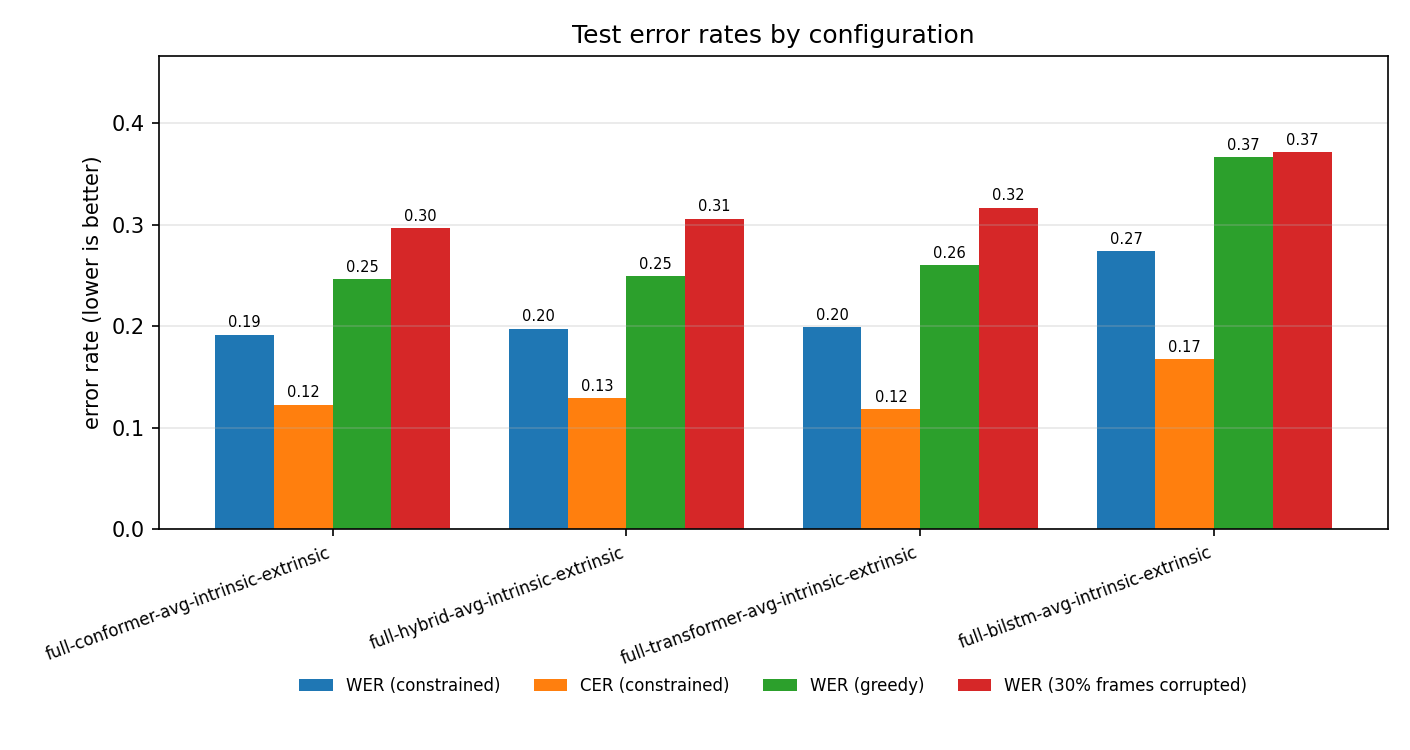

In [15]:
import pandas as pd
compare_dir = RUN_DIR if ABLATION_RUN else f"{OUTPUT_DIR}/runs"
if RUN_TRAINING and os.path.isdir(compare_dir):
    try:
        run(f"python scripts/compare_runs.py {compare_dir}")
        df_cmp = pd.read_csv(f"{compare_dir}/comparison.csv").set_index("run")
        display(df_cmp.round(3))
        from IPython.display import Image
        display(Image(f"{compare_dir}/comparison.png", width=900))
    except RuntimeError as e:
        print("Nothing to compare yet:", e)
else:
    print("Training is off.")

## 14. Training curves (single mode)
Plots the per-epoch losses, the validation word / character error rates (greedy decoding) and the per-frame
validation accuracies from `training_metrics.csv`, and saves the figure to the run folder. *Speech-only*
accuracy excludes silence frames, which make up about half of every GRID clip.

In [16]:
import pandas as pd
metrics_csv = f"{RUN_DIR}/training_metrics.csv"
if SINGLE_RUN and os.path.exists(metrics_csv):
    df = pd.read_csv(metrics_csv).set_index("epoch")
    fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(17, 4.5))
    df[["train_total_loss", "val_total_loss", "train_ctc_loss", "val_ctc_loss"]].plot(ax=ax1, marker="o", title="Losses")
    df[["val_wer", "val_cer"]].plot(ax=ax2, marker="o", title="Validation error rate (greedy)", ylim=(0, 1))
    acc_cols = ["val_speech_viseme_accuracy", "val_speech_phoneme_accuracy"]
    df[acc_cols].plot(ax=ax3, marker="o", title="Validation per-frame accuracy (speech only)", ylim=(0, 1))
    for ax in (ax1, ax2, ax3):
        ax.grid(alpha=0.3)
    plt.tight_layout(); plt.savefig(f"{RUN_DIR}/training_curves.png", dpi=150); plt.show()
    display(df.round(4))
else:
    print("No metrics yet.")

No metrics yet.


## 15. Evaluate the best checkpoint on the test speakers (single mode)
Runs `main.py evaluate` on `best_model.pth` (the model settings are read from the checkpoint) and writes the
report, JSON and confusion matrices to `runs/<RUN_NAME>/evaluation/`. It reports word / character error rate
for greedy and GRID-grammar-constrained decoding, per-slot accuracy, the letter-slot homophene analysis
(letters that look identical on the lips, e.g. b/p) and the mean fusion-gate weights by frame type.

If `CORRUPT_RATIO` > 0, the evaluation is repeated with about that share of every test clip's frames replaced
and flagged as unreliable - the controlled robustness test for the intrinsic-extrinsic gate.

In [17]:
best = f"{RUN_DIR}/best_model.pth"
if SINGLE_RUN and os.path.exists(best):
    eval_dir = f"{RUN_DIR}/evaluation"
    base = (f"python main.py evaluate --data-dir {LOCAL_DATA} --test-subjects {TEST_SPEAKERS} "
            f"--batch-size {BATCH_SIZE} --num-workers {NUM_WORKERS} --checkpoint-path {best} --results-dir {eval_dir}")
    run(base)
    if CORRUPT_RATIO > 0:
        run(f"{base} --corrupt-ratio {CORRUPT_RATIO}")
    rows = {}
    for name in sorted(os.listdir(eval_dir)):
        if name.startswith("evaluation_results") and name.endswith(".json"):
            r = json.load(open(f"{eval_dir}/{name}"))
            rows[name[len("evaluation_results"):-5] or "clean"] = {
                "greedy WER": r["greedy"]["wer"], "greedy CER": r["greedy"]["cer"],
                "constrained WER": r["constrained"]["wer"], "constrained CER": r["constrained"]["cer"],
                "letter acc": r["constrained"]["letter_slot"]["accuracy"],
                "homophene-letter acc": r["constrained"]["letter_slot"]["homophene_letter_accuracy"],
                "speech phoneme acc": r["frame"]["speech_phoneme_accuracy"]}
    display(pd.DataFrame(rows).T.round(4))
    from IPython.display import Image
    for png in ("viseme_confusion_matrix.png", "phoneme_confusion_matrix.png"):
        if os.path.exists(f"{eval_dir}/plots/{png}"):
            display(Image(f"{eval_dir}/plots/{png}", width=700))
else:
    print("No trained model to evaluate.")

No trained model to evaluate.


## 16. Inference demo (single mode)
Runs `main.py inference` on a few test utterances and prints, for each, the reference sentence, the greedy and
grammar-constrained decoded sentences, the per-frame phoneme sequence and the average visual/language fusion
weights.

In [18]:
if SINGLE_RUN and os.path.exists(best):
    run(f"python main.py inference --data-dir {LOCAL_DATA} --test-subjects {TEST_SPEAKERS} "
        f"--checkpoint-path {best} --demo-samples {DEMO_SAMPLES} --batch-size {BATCH_SIZE}")
else:
    print("No trained model.")

No trained model.


## 17. Save logs to Drive
Copies the full text log (`lipreading.log`) and the TensorBoard logs (`runs/`) from the Colab VM into the run
folder, so everything about the run is on Drive. (Checkpoints, metrics and test results are already there.)

In [19]:
if RUN_TRAINING:
    if os.path.exists(f"{REPO_DIR}/lipreading.log"):
        shutil.copy(f"{REPO_DIR}/lipreading.log", RUN_DIR)
    if os.path.isdir(f"{REPO_DIR}/runs"):
        shutil.copytree(f"{REPO_DIR}/runs", f"{RUN_DIR}/tensorboard", dirs_exist_ok=True)
    print("Run folder contents:")
    for f in sorted(os.listdir(RUN_DIR)):
        print("  ", f)
else:
    print("Training is off.")

Run folder contents:
   ablation.json
   comparison.csv
   comparison.md
   comparison.png
   full-bilstm-avg-intrinsic-extrinsic
   full-conformer-avg-intrinsic-extrinsic
   full-hybrid-avg-intrinsic-extrinsic
   full-transformer-avg-intrinsic-extrinsic
   lipreading.log
   tensorboard


## Using the preprocessed data on a local machine
Download from Drive, for each speaker:
- `Lipreading_advanced_preprocessing/preprocessed/<PREPROCESS_TAG>/sN_preprocessed.tar.gz`
- `Lipreading_advanced_preprocessing/alignments/sN_alignments.tar.gz`

Then, from the repository folder:

```bash
mkdir -p data/preprocessed_lips data/alignments
tar -xzf ~/Downloads/s1_preprocessed.tar.gz -C data/preprocessed_lips
tar -xzf ~/Downloads/s1_alignments.tar.gz   -C data/alignments
# quick local run (Apple Silicon GPU is used automatically)
python main.py train --local-checkpoints --train-subjects s1 --val-subjects s2 --test-subjects s2 --num-epochs 2
```
The raw videos are not needed locally.